# Лабораторная работа №5. Регуляризация

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import helpers as h
import importlib
from datetime import datetime
importlib.reload(h)
print(f"Модуль обновлён в {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
import warnings
warnings.filterwarnings("ignore")

Модуль обновлён в 2026-10-23 13:11:23


In [2]:
def graph_setup():
    sns.set_style("whitegrid")
    sns.set_context("notebook", font_scale=1.2)
    plt.rcParams['figure.figsize'] = [8, 6]
    plt.rcParams['figure.dpi'] = 100

graph_setup()

## Решение

In [3]:
data = np.loadtxt("ex2data2.txt", delimiter=",")
X_init = data[:, :(-1)]
y = data[:, -1]
X, mean, std = h.normalize(X_init)
neg_indices = np.where(y == 0)[0]
pos_indices = np.where(y == 1)[0]
X_neg = X[neg_indices]
X_pos = X[pos_indices]

In [8]:
%%time
epochs = 50_000
alpha = 0.01
lam_underfit = 90.0
lam_underfit2 = 87.0
lam_good = 0.9
lam_overfit = 0.0

clf = h.CustomClassifier()
clf.fit(X, y, alpha=alpha, lam=lam_overfit, epochs=epochs)
print(f"Переобучение; accuracy: {h.accuracy(y, clf.predict(X)):.2f}")


clf_lasso = h.CustomClassifier()
clf_lasso.fit(X, y, alpha=alpha, lam=lam_good, epochs=epochs, method="lasso")
print(f"Lasso регуляризация; accuracy: {h.accuracy(y, clf_lasso.predict(X)):.2f}")

clf_ridge = h.CustomClassifier()
clf_ridge.fit(X, y, alpha=alpha, lam=lam_good, epochs=epochs, method="ridge")
print(f"Ridge регуляризация; accuracy: {h.accuracy(y, clf_ridge.predict(X)):.2f}")

clf_elastic = h.CustomClassifier()
clf_elastic.fit(X, y, alpha=alpha, lam=lam_good, lam2=lam_good, epochs=epochs, method="elastic")
print(f"Elastic регуляризация; accuracy: {h.accuracy(y, clf_elastic.predict(X)):.2f}")


clf_lasso_und = h.CustomClassifier()
clf_lasso_und.fit(X, y, alpha=alpha, lam=lam_underfit, epochs=epochs, method="lasso")
print(f"Lasso регуляризация (недообучение); accuracy: {h.accuracy(y, clf_lasso_und.predict(X)):.2f}")

clf_ridge_und = h.CustomClassifier()
clf_ridge_und.fit(X, y, alpha=alpha, lam=lam_underfit2, epochs=epochs, method="ridge")
print(f"Ridge регуляризация (недообучение); accuracy: {h.accuracy(y, clf_ridge_und.predict(X)):.2f}")

clf_elastic_und = h.CustomClassifier()
clf_elastic_und.fit(X, y, alpha=alpha, lam=lam_underfit, lam2=lam_underfit, epochs=epochs, method="elastic")
print(f"Elastic регуляризация (недообучение); accuracy: {h.accuracy(y, clf_elastic_und.predict(X)):.2f}")


Переобучение; accuracy: 0.85
Lasso регуляризация; accuracy: 0.76
Ridge регуляризация; accuracy: 0.80
Elastic регуляризация; accuracy: 0.76
Lasso регуляризация (недообучение); accuracy: 0.60
Ridge регуляризация (недообучение); accuracy: 0.65
Elastic регуляризация (недообучение); accuracy: 0.48
CPU times: total: 19 s
Wall time: 19.4 s


In [9]:
[clf.theta.max(), clf_lasso.theta.max(), clf_ridge.theta.max(), clf_elastic.theta.max()]

[np.float64(6.682323063572021),
 np.float64(0.2694423126042371),
 np.float64(1.106631656546258),
 np.float64(0.22969306727762723)]

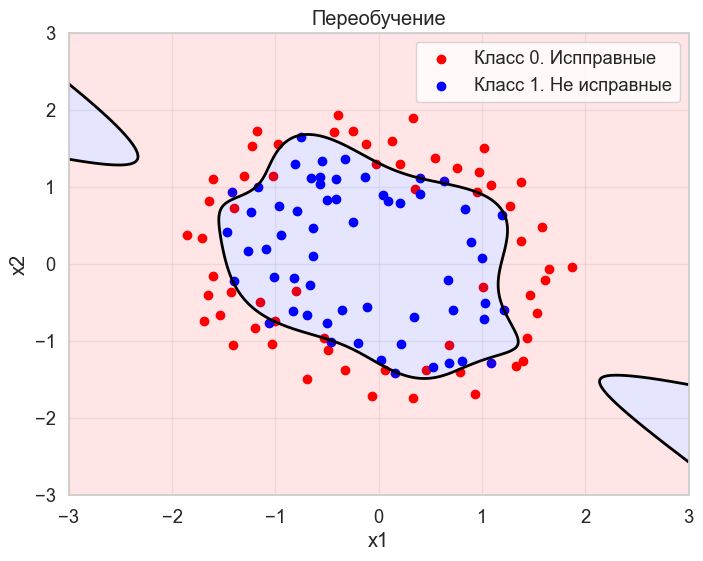

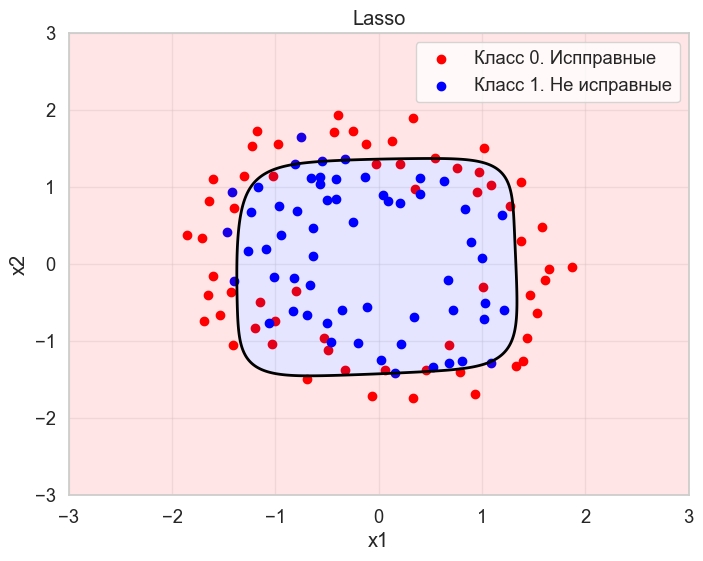

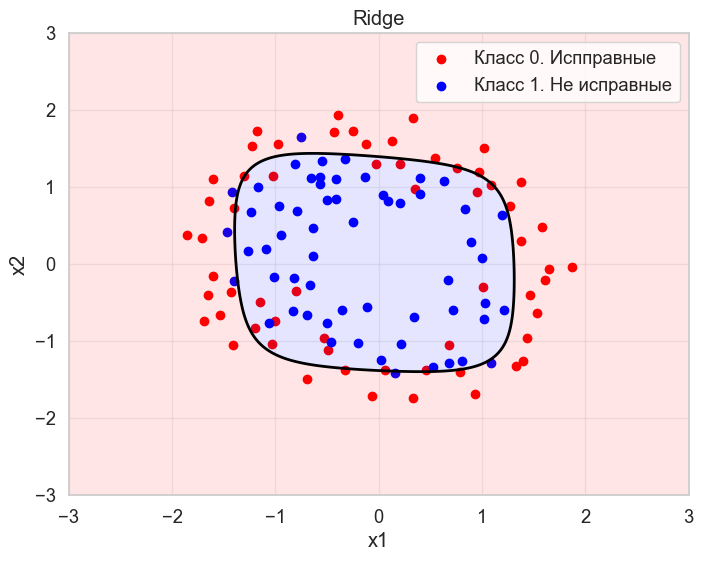

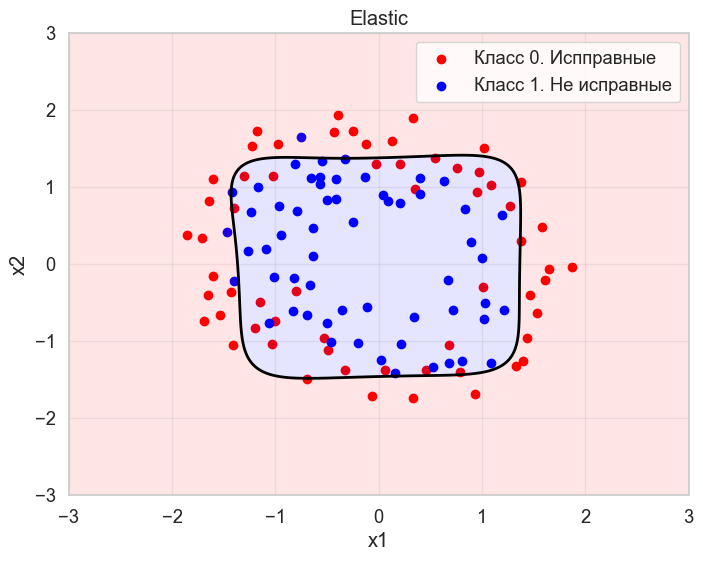

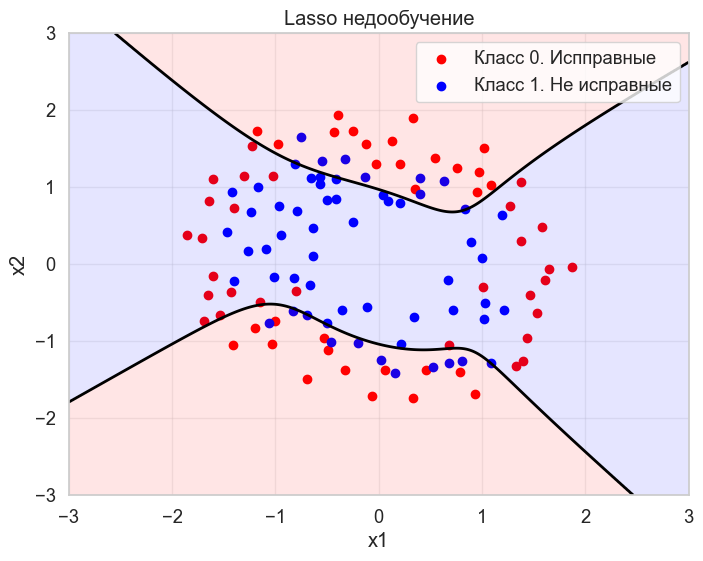

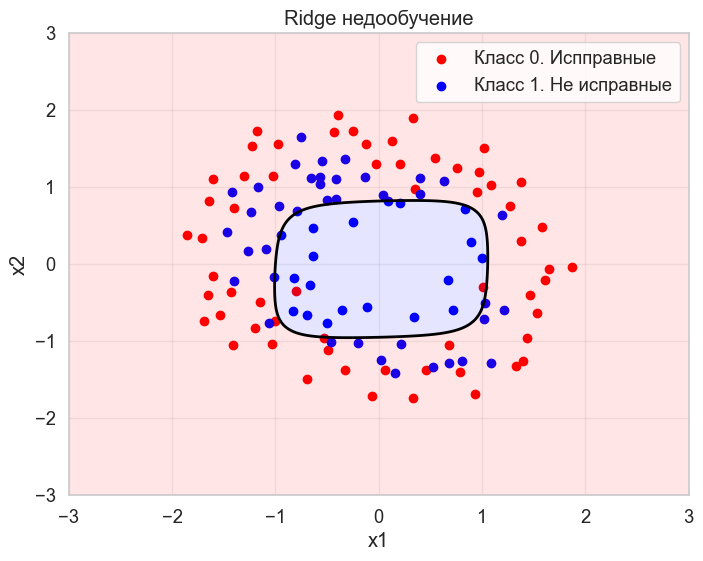

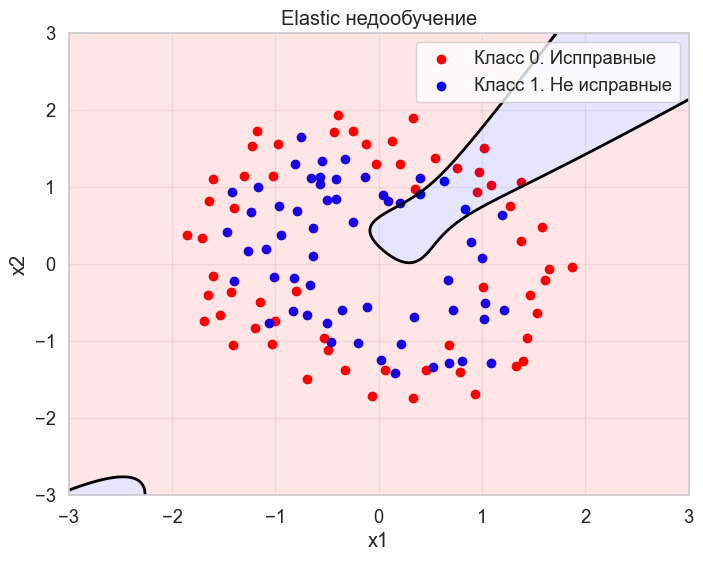

In [10]:
classifiers = [clf, clf_lasso, clf_ridge, clf_elastic, clf_lasso_und, clf_ridge_und, clf_elastic_und]
h.plotLines(X_neg, X_pos, classifiers)